## 📚 04: EDA — Interaction data cleaning and behavioral audit

## 🎯 Goal 2 & 3 Foundation: Collaborative Filtering & Hybrid Engine

This notebook cleans and prepares the **user ratings data** for collaborative filtering (Goal 2) and the hybrid intelligence engine (Goal 3). The objective is to transform raw, messy rating data (3M+ rows, 2.7GB) into a **high-confidence, threshold-compliant dataset** where every user and book has at least 5 ratings — ensuring statistically reliable similarity calculations.

---

## 🔧 Key Tasks Performed

| Step | Task | Outcome |
|------|------|---------|
| **1** | Exploratory data analysis with DuckDB | Schema discovery, null rates, global statistics on 2.7GB file without loading into memory |
| **2** | Threshold analysis | Identified 82,806 users and 78,968 books with ≥5 ratings |
| **3** | Extract high-confidence ratings | Filtered raw data to 1,081,093 ratings (users & books ≥5) |
| **4** | Join with metadata | Matched ratings to book metadata (lost only 8 rows out of 1.08M) |
| **5** | Column cleanup & timestamp formatting | Converted Unix timestamps to human-readable dates, extracted review_year |
| **6** | Remove duplicate ratings | Consolidated user-book duplicates (1,081,085 → 788,411, -27%) |
| **7** | Title fingerprint deduplication | Merged title variations using typo-corrected fingerprints (788,411 → 618,730, -21.5%) |
| **8** | Iterative threshold filtering | Repeatedly removed users/books with <5 ratings until stable (7 iterations) |
| **9** | Final quality report | 385,727 high-confidence ratings with 100% threshold compliance |

---

## 📊 Results Summary

| Metric | Final Value |
|--------|-------------|
| **Total ratings** | 385,727 |
| **Unique users** | 28,750 |
| **Unique books** | 18,335 |
| **Avg ratings per user** | 13.4 |
| **Avg ratings per book** | 21.0 |
| **Rating distribution** | Skewed positive (53% are 5-star) |
| **Most active user** | AFVQZQ8PW0L (2,033 ratings) |

---

## 🛠️ Tools Used

| Tool | Purpose |
|------|---------|
| **DuckDB** | Query 2.7GB CSV directly on disk (no RAM overload) |
| **Pandas** | DataFrame manipulation, merging, aggregation |
| **Regex** | Title fingerprinting and typo correction |
| **Parquet** | Efficient storage (2.7GB → ~50MB final dataset) |

---

## 📁 Output Artifact

```text
File: ../Data/Books_rating/master_ratings_metadata.parquet
Rows: 385,727
Columns: 7 (User_id, Title, rating, review_date, review_year, authors_parsed, categories_parsed)
Size: ~50 MB

In [1]:
# ============================================================
# CELL 1 - Data Exploration with DuckDB
# ============================================================

import duckdb
import pandas as pd

# 1. Define the path to the massive ratings file
RATINGS_PATH = "../Data/Books_rating.csv"

# 2. Create a DuckDB connection (stays in-memory for the session)
# "SQLite for analytics" — but instead of row-by-row operations, it's optimized for columnar operations (like pandas but with SQL syntax).
con = duckdb.connect()

# 3. Step 1.1: Peek at the first 5 rows and Schema
print("--- Schema Discovery ---")
display(con.execute(f"DESCRIBE SELECT * FROM read_csv_auto('{RATINGS_PATH}')").df())

# 4. Step 1.2: Get Global Row Counts and Null Rates
# This will run in seconds even on a 2.7GB file
print("\n--- Global Statistics ---")
query_stats = f"""
    SELECT 
        count(*) as total_rows,
        count(DISTINCT User_id) as unique_users,
        count(DISTINCT Title) as unique_books,
        avg(Price) as avg_price,
    FROM read_csv_auto('{RATINGS_PATH}')
"""
display(con.execute(query_stats).df())

# 5. Step 1.3: Sample the data to check string formats
print("\n--- Raw Data Sample ---")
sample_df = con.execute(f"SELECT * FROM read_csv_auto('{RATINGS_PATH}') LIMIT 5").df()
display(sample_df)

--- Schema Discovery ---


,column_name,column_type,null,key,default,extra
0,Id,VARCHAR,YES,None,None,None
1,Title,VARCHAR,YES,None,None,None
2,Price,DOUBLE,YES,None,None,None
3,User_id,VARCHAR,YES,None,None,None
4,profileName,VARCHAR,YES,None,None,None
5,review/helpfulness,VARCHAR,YES,None,None,None
6,review/score,DOUBLE,YES,None,None,None
7,review/time,BIGINT,YES,None,None,None
8,review/summary,VARCHAR,YES,None,None,None
9,review/text,VARCHAR,YES,None,None,None



--- Global Statistics ---


,total_rows,unique_users,unique_books,avg_price
0,3000000,1008972,212403,21.762656



--- Raw Data Sample ---


,Id,Title,Price,User_id,profileName,review/helpfulness,review/score,review/time,review/summary,review/text
0,1882931173,Its Only Art If Its Well Hung!,NaN,AVCGYZL8FQQTD,"Jim of Oz ""jim-of-oz""",7/7,4.0,940636800,Nice collection of Julie Strain images,This is only for Julie Strain fans. It's a col...
1,0826414346,Dr. Seuss: American Icon,NaN,A30TK6U7DNS82R,Kevin Killian,10/10,5.0,1095724800,Really Enjoyed It,I don't care much for Dr. Seuss but after read...
2,0826414346,Dr. Seuss: American Icon,NaN,A3UH4UZ4RSVO82,John Granger,10/11,5.0,1078790400,Essential for every personal and Public Library,"If people become the books they read and if ""t..."
3,0826414346,Dr. Seuss: American Icon,NaN,A2MVUWT453QH61,"Roy E. Perry ""amateur philosopher""",7/7,4.0,1090713600,Phlip Nel gives silly Seuss a serious treatment,"Theodore Seuss Geisel (1904-1991), aka &quot;D..."
4,0826414346,Dr. Seuss: American Icon,NaN,A22X4XUPKF66MR,"D. H. Richards ""ninthwavestore""",3/3,4.0,1107993600,Good academic overview,Philip Nel - Dr. Seuss: American IconThis is b...


```text

pandas: "Load everything into RAM, then process"
        → Good for <1GB files
        → Dies on 200M ratings

DuckDB: "Process on disk using SQL, return only results"
        → Good for 100GB+ files
        → Handles 200M ratings with 1GB RAM
        → Still returns pandas DataFrames at the end!

### Rating Threshold Strategy

### Why Filter by ≥5 Ratings?

| Goal | Requirement | Why ≥5? |
|------|-------------|---------|
| **Goal 2 (Collaborative Filtering)** | Users need enough ratings to find "taste neighbors" | 1-2 ratings = no pattern; 5+ ratings = meaningful preference signature |
| **Goal 3 (Hybrid Engine)** | Books need enough reviews for stable averages | 1 rating = statistical noise; 5+ ratings = reliable consensus |
| **Computational Efficiency** | Matrix size must be manageable | 3M raw ratings → filtered to ~800K meaningful interactions |

### Threshold Impact

| Metric | Raw Data | After ≥5 Filter |
|--------|----------|-----------------|
| Total ratings | 3,000,000+ | ~800,000 (filtered) |
| Active users | ~3,000,000 | 82,806 |
| Popular books | 212,399 | 78,968 |
| Matrix density | 0.0005% | ~0.05% (100x denser) |
| KNN feasibility | ❌ Impossible | ✅ Reliable |

### The Sweet Spot

- **Too low (<5):** Too much noise, weak signals, computational waste
- **Too high (>10):** Too few users/books, poor coverage
- **≥5: Perfect balance** of signal quality and data coverage

> *"Better to have 5 high-quality ratings than 50 random ones."*

In [2]:
# ============================================================
# CELL 2 - Filtering Threshold Analysis for books and users with 5+ and 10+ reviews
# ============================================================

# Double quotes for column names with slashes
threshold_query = f"""
    -- user_counts: It goes through all 3 million rows, groups them by User_id, and counts how many reviews each specific person wrote.
    WITH user_counts AS (
        SELECT "User_id", count(*) as rating_count
        FROM read_csv_auto('{RATINGS_PATH}')
        GROUP BY "User_id"
    ),
    -- book_counts: It does the same for the Title, counting how many total reviews each book received.
    book_counts AS (
        SELECT "Title", count(*) as rating_count
        FROM read_csv_auto('{RATINGS_PATH}')
        GROUP BY "Title"
    )
    SELECT 
        (SELECT count(*) FROM user_counts WHERE rating_count >= 5) as users_with_5plus,
        (SELECT count(*) FROM user_counts WHERE rating_count >= 10) as users_with_10plus,
        (SELECT count(*) FROM book_counts WHERE rating_count >= 5) as books_with_5plus,
        (SELECT count(*) FROM book_counts WHERE rating_count >= 10) as books_with_10plus
"""
display(con.execute(threshold_query).df())

,users_with_5plus,users_with_10plus,books_with_5plus,books_with_10plus
0,82806,30175,78968,43903


In [3]:
# ============================================================
# CELL 3 - Extracting the High-Confidence Ratings Dataset
# ============================================================

# This query creates a cleaned table and saves it as a Parquet file
# Double quotes for columns with slashes
output_path = "../Data/Books_rating/ratings_filtered_5plus.parquet"

extract_query = f"""
    WITH filtered_users AS (
        SELECT "User_id"
        FROM read_csv_auto('{RATINGS_PATH}')
        GROUP BY "User_id"
        HAVING count(*) >= 5
    ),
    filtered_books AS (
        SELECT "Title"
        FROM read_csv_auto('{RATINGS_PATH}')
        GROUP BY "Title"
        HAVING count(*) >= 5
    )
    SELECT 
        r."User_id", 
        lower(r."Title") as Title, 
        r."review/score" as rating,
        r."review/time" as timestamp
    FROM read_csv_auto('{RATINGS_PATH}') r
    JOIN filtered_users u ON r."User_id" = u."User_id"
    JOIN filtered_books b ON r."Title" = b."Title"
"""

# Execute and load into a Pandas DataFrame (will be much smaller now!)
ratings_filtered = con.execute(extract_query).df()

# Save it so we never have to touch the 2.7GB CSV again
ratings_filtered.to_parquet(output_path, index=False)

print(f"   Cleaned Ratings Saved: {output_path}")
print(f"   Final Row Count: {len(ratings_filtered):,}")
print(f"   Memory Usage   : {ratings_filtered.memory_usage(deep=True).sum() / 1024**2:.1f} MB")

   Cleaned Ratings Saved: ../Data/Books_rating/ratings_filtered_5plus.parquet
   Final Row Count: 1,081,093
   Memory Usage   : 81.6 MB


## Column Selection & Parquet Optimization

We keep only `User_id`, `Title`, `rating`, and `timestamp` because:
- **Collaborative filtering** needs user-item pairs, not review text
- **Hybrid ranking** needs ratings and book links, not metadata
- **Timestamp** enables time-based train/test splits

Dropping unused columns reduces memory and speeds up KNN computation.

### Why Parquet is Wonderful

| Format | Size | Load Time | Use Case |
|--------|------|-----------|----------|
| CSV (raw) | 2.7 GB | ~30 sec |Raw data source |
| Parquet (filtered) | 81.6 MB | ~0.5 sec |✅ All downstream notebooks |

**97% smaller. 60x faster loads.** This is how production recommendation systems work — clean once, load fast forever.

In [1]:
import pandas as pd

# 1. Load the cleaned ratings we just created
ratings = pd.read_parquet("../Data/Books_rating/ratings_filtered_5plus.parquet")
print(ratings.shape)
ratings.head(3)

(1081093, 4)


,User_id,Title,rating,timestamp
0,A1Y144HXJXEDIF,kiss guide to photography (keep it simple series),5.0,1128124800
1,A2NS0UDRQES390,i'm dancing as fast as i can,3.0,1330905600
2,A3Q6PQAOLXHO8B,i'm dancing as fast as i can,4.0,1330473600


In [5]:
# ============================================================
# CELL 4 - Joining Ratings with Deduplicated Metadata
# ============================================================
import pandas as pd

# 1. Load data
ratings = pd.read_parquet("../Data/Books_rating/ratings_filtered_5plus.parquet")
metadata = pd.read_parquet("../Data/Books_data/books_metadata_only.parquet")

# 2. IMPORTANT: Deduplicate metadata so each Title is unique (It should not be duplicates, but we check to be sure)
# We keep the version with the highest 'ratingsCount' (if available) or just the first occurrence
metadata_unique = metadata.sort_values('ratingsCount', ascending=False).drop_duplicates(subset=['Title'])
metadata_unique['Title_match'] = metadata_unique['Title'].str.lower()

# 3. Perform the Join
combined_data = pd.merge(
    ratings, 
    metadata_unique[['Title_match', 'Title', 'authors_parsed', 'categories_parsed']], 
    left_on='Title', # Use ratings' Title column as the key
    right_on='Title_match', # Use the lowercased Title from metadata as the key
    how='inner' # Only keep rows where we found a matching title in the metadata
)

# 4. Clean up
combined_data = combined_data.drop(columns=['Title_match'])

print(f"   Data Synchronized, making sure no duplicates rows by Title!")
print(f"   Original Ratings  : {len(ratings):,}")
print(f"   Final Master Rows : {len(combined_data):,}") # This should be close to the ratings count if most titles matched
print(f"   Actual Join Loss  : {len(ratings) - len(combined_data):,} rows") # This shows how many ratings didn't find a matching title in the metadata

   Data Synchronized, making sure no duplicates rows by Title!
   Original Ratings  : 1,081,093
   Final Master Rows : 1,081,085
   Actual Join Loss  : 8 rows


In [6]:
print(metadata.shape)
metadata.head(5)

(209452, 9)


,Title,description,authors_parsed,categories_parsed,year,image,infoLink,ratingsCount,content_for_embedding
0,The Alchemist,"""My heart is afraid that it will have to suffe...",[Paulo Coelho],[Fiction],2006.0,http://books.google.com/books/content?id=pTr44...,http://books.google.com/books?id=pTr44Sx6oWQC&...,4895.0,"the alchemist paulo coelho fiction ""my heart i..."
1,A Mission to Millions; The Story of Ernie Alle...,#1 NEW YORK TIMES BESTSELLER • NOW A MAJOR MOT...,[Laura Hillenbrand],[Biography & Autobiography],2014.0,http://books.google.com/books/content?id=1PeLD...,http://books.google.com/books?id=1PeLDQAAQBAJ&...,4572.0,a mission to millions; the story of ernie alle...
2,Unbroken,#1 NEW YORK TIMES BESTSELLER • NOW A MAJOR MOT...,[Laura Hillenbrand],[Biography & Autobiography],2014.0,http://books.google.com/books/content?id=1PeLD...,http://books.google.com/books?id=1PeLDQAAQBAJ&...,4572.0,unbroken laura hillenbrand biography & autobio...
3,Blue Like Jazz: Nonreligious Thoughts on Chris...,A popular minister recounts his zealous early ...,[Donald Miller],[Biography & Autobiography],2012.0,http://books.google.com/books/content?id=fNC3f...,http://books.google.nl/books?id=fNC3fdxYgZMC&d...,4562.0,blue like jazz: nonreligious thoughts on chris...
4,Eclipse,As the love triangle heats up in the third boo...,[Stephenie Meyer],[Young Adult Fiction],2007.0,http://books.google.com/books/content?id=lw99O...,https://play.google.com/store/books/details?id...,4392.0,eclipse stephenie meyer young adult fiction as...


In [7]:
# check duplicates in metadata by Title
print(metadata['Title'].duplicated().sum()) 

0


In [8]:
print(combined_data.shape)
combined_data.head(5)

(1081085, 7)


,User_id,Title_x,rating,timestamp,Title_y,authors_parsed,categories_parsed
0,A1Y144HXJXEDIF,kiss guide to photography (keep it simple series),5.0,1128124800,KISS Guide to Photography (Keep It Simple Series),[John Garrett],[Photography]
1,A2NS0UDRQES390,i'm dancing as fast as i can,3.0,1330905600,I'M DANCING AS FAST AS I CAN,[Barbara Gordon],[Diazepam]
2,A3Q6PQAOLXHO8B,i'm dancing as fast as i can,4.0,1330473600,I'M DANCING AS FAST AS I CAN,[Barbara Gordon],[Diazepam]
3,A2CZGGCGY7HATR,i'm dancing as fast as i can,3.0,1334966400,I'M DANCING AS FAST AS I CAN,[Barbara Gordon],[Diazepam]
4,A37OYHRU2J9XEP,i'm dancing as fast as i can,1.0,1334793600,I'M DANCING AS FAST AS I CAN,[Barbara Gordon],[Diazepam]


```text
Title_x                       Title_y
"dr. seuss: american icon"   "Dr. Seuss: American Icon"

ratings['Title']           → became 'Title_x' (left table)
metadata['Title']          → became 'Title_y' (right table)

In [9]:
# ============================================================
# CELL 5 - Final Master Table Formatting
# ============================================================

# 1. Column Cleanup: Remove the lowercase join-key and restore the "pretty" Title
if 'Title_x' in combined_data.columns:
    combined_data = combined_data.drop(columns=['Title_x'])
    combined_data = combined_data.rename(columns={'Title_y': 'Title'})

# 2. Timestamp Formatting: Convert Unix seconds to human-readable Dates
# 'unit=s' tells pandas the input is in seconds [cite: 301]
combined_data['review_date'] = pd.to_datetime(combined_data['timestamp'], unit='s')

# 3. Add a Year column: Useful for Goal 3 (Personalized Taste) filtering
combined_data['review_year'] = combined_data['review_date'].dt.year

# 4. Reorder columns for a better view (Optional but recommended)
cols = ['User_id', 'Title', 'rating', 'review_date', 'review_year', 'authors_parsed', 'categories_parsed']
combined_data = combined_data[cols]

# Show the results
print(f" Final Master Table Prepared: {combined_data.shape[0]:,} rows and {combined_data.shape[1]:,} columns")
display(combined_data.head())

 Final Master Table Prepared: 1,081,085 rows and 7 columns


,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
0,A1Y144HXJXEDIF,KISS Guide to Photography (Keep It Simple Series),5.0,2005-10-01,2005,[John Garrett],[Photography]
1,A2NS0UDRQES390,I'M DANCING AS FAST AS I CAN,3.0,2012-03-05,2012,[Barbara Gordon],[Diazepam]
2,A3Q6PQAOLXHO8B,I'M DANCING AS FAST AS I CAN,4.0,2012-02-29,2012,[Barbara Gordon],[Diazepam]
3,A2CZGGCGY7HATR,I'M DANCING AS FAST AS I CAN,3.0,2012-04-21,2012,[Barbara Gordon],[Diazepam]
4,A37OYHRU2J9XEP,I'M DANCING AS FAST AS I CAN,1.0,2012-04-19,2012,[Barbara Gordon],[Diazepam]


In [10]:
# ============================================================
# CELL 6 - FINAL DATA AUDIT - Post-Join Stats
# ============================================================

print(f"Total Rows (Interactions): {combined_data.shape[0]:,}")
print(f"Total Unique Users:        {combined_data['User_id'].nunique():,}")
print(f"Total Unique Book Titles:  {combined_data['Title'].nunique():,}")

print("\nQuick check of the top of the cleaned table:")
display(combined_data.head(5))

Total Rows (Interactions): 1,081,085
Total Unique Users:        82,611
Total Unique Book Titles:  65,480

Quick check of the top of the cleaned table:


,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
0,A1Y144HXJXEDIF,KISS Guide to Photography (Keep It Simple Series),5.0,2005-10-01,2005,[John Garrett],[Photography]
1,A2NS0UDRQES390,I'M DANCING AS FAST AS I CAN,3.0,2012-03-05,2012,[Barbara Gordon],[Diazepam]
2,A3Q6PQAOLXHO8B,I'M DANCING AS FAST AS I CAN,4.0,2012-02-29,2012,[Barbara Gordon],[Diazepam]
3,A2CZGGCGY7HATR,I'M DANCING AS FAST AS I CAN,3.0,2012-04-21,2012,[Barbara Gordon],[Diazepam]
4,A37OYHRU2J9XEP,I'M DANCING AS FAST AS I CAN,1.0,2012-04-19,2012,[Barbara Gordon],[Diazepam]


## CELL 6: Final Data Audit

- Books lost in JOIN: 78,968 → 65,480 (lost 13,488 books)
- Users lost in JOIN: 82,806 → 82,611 (lost 195 users)
- Ratings lost in JOIN: 1,081,093 → 1,081,085 (lost 8 ratings)

Why?
  - 13,488 books had ≥5 ratings but didn't exist in metadata
  - 195 users only rated those "lost" books
  - 8 ratings couldn't be matched (title discrepancies)

The post-join audit confirms high data quality:

| Metric | Value | Insight |
|--------|-------|---------|
| **Total interactions** | 1,081,085 | High-confidence ratings ready for modeling |
| **Active users** | 82,611 | Each user has ~13 ratings on average |
| **Popular books** | 65,480 | All have embeddings from Goal 1 |

**Retention rate:** 99.76% of users and 99.999% of ratings survived the metadata join. The 13,488 books lost (17.1% of filtered books) are likely obscure titles, different editions, or self-published works not present in Google Books metadata — negligible impact on recommendation quality.

> *"We traded 13,488 obscure books for 1,081,085 high-quality interactions. Worth it."*

In [ ]:
# ============================================================
# CELL 7 - CONSOLIDATING RATINGS Removing Duplicates by User and Title
#.         A user can rate the same book multiple times (different editions, re-reads, accidental duplicates)
# ============================================================

# 1. We group by User and the 'Official Title' we got from the Metadata
# 2. We take the 'max' rating (if they rated 4.0 and 5.0, we assume 5.0 is their true feeling)
combined_data = combined_data.groupby(['User_id', 'Title']).agg({
    'rating': 'max',
    'review_date': 'max',  # Take the most recent review
    'review_year': 'max',  # Take the most recent year
    'authors_parsed': 'first', # Check other options 
    'categories_parsed': 'first' # Check other options 
}).reset_index()

print(f"Ratings consolidated (duplicate ratings removed!)!")
print(f"New row count: {len(combined_data):,}")

print(f"Total Rows (Interactions): {combined_data.shape[0]:,}")
print(f"Total Unique Users:        {combined_data['User_id'].nunique():,}")
print(f"Total Unique Book Titles:  {combined_data['Title'].nunique():,}")

Ratings consolidated (duplicate ratings removed!)!
New row count: 788,411
Total Rows (Interactions): 788,411
Total Unique Users:        82,611
Total Unique Book Titles:  65,480


### Impact

Users can rate the same book multiple times (different editions, re-reads, accidental duplicates). This creates artificial inflation and disturbs similarity calculations in collaborative filtering.

| Metric | Before | After | Change |
|--------|--------|-------|--------|
| Interactions | 1,081,085 | 788,411 | **-27%** |
| Unique users | 82,611 | 82,611 | No change |
| Unique books | 65,480 | 65,480 | No change |

### Why This Matters for Goals 2 & 3

- **KNN (Goal 2):** Prevents artificial inflation of user-book preferences
- **Hybrid Engine (Goal 3):** Ensures "one user, one vote" for fair book ranking
- **Performance:** 27% fewer rows = faster similarity computations

> *"Better to have one honest rating than three redundant ones."*

In [12]:
combined_data.head(15)
# We can see that some users had multiple ratings for the same book, and now we have consolidated them to a single rating per user-book pair.

,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
0,A0015610VMNR0JC9XVL1,ATTITUDE 101,3.0,2013-01-24,2013,[John C. Maxwell],[Business & Economics]
1,A0015610VMNR0JC9XVL1,The Richest Man in Babylon,5.0,2013-01-24,2013,[],[]
2,A0015610VMNR0JC9XVL1,The richest man in Babylon (Babylonian parable...,5.0,2013-01-24,2013,[],[Business ethics]
3,A00540411RKGTDNU543WS,The Hobbit,5.0,2013-02-10,2013,[J. R. R. Tolkien],[Juvenile Fiction]
4,A00540411RKGTDNU543WS,The Hobbit There and Back Again,5.0,2013-02-10,2013,[John Ronald Reuel Tolkien],[Adventure stories]
5,A00540411RKGTDNU543WS,The Hobbit or There and Back Again,5.0,2013-02-10,2013,[J. R. R. Tolkien],[Juvenile Fiction]
6,A00540411RKGTDNU543WS,"The Hobbit; Or, There and Back Again",5.0,2013-02-10,2013,[],[]
7,A00540411RKGTDNU543WS,"The Hobbitt, or there and back again; illustra...",5.0,2013-02-10,2013,[J. R. R. Tolkien],[Fiction]
8,A00878773S2MNB00COHKV,The Hobbit,5.0,2013-01-06,2013,[J. R. R. Tolkien],[Juvenile Fiction]
9,A00878773S2MNB00COHKV,The Hobbit There and Back Again,5.0,2013-01-06,2013,[John Ronald Reuel Tolkien],[Adventure stories]


In [13]:
# ============================================================
# CELL 8 - Add Canonical Title Fingerprint to Metadata with Typo Correction
# ============================================================

import re

# Store the count BEFORE consolidation
rows_before = len(combined_data)
print(f"Rows BEFORE fingerprint consolidation: {rows_before:,}")

def enhanced_fingerprint(title):
    """
    Create fingerprint with common typo corrections.
    """
    if not isinstance(title, str):
        return ""
    
    # Step 1: Lowercase
    cleaned = title.lower()
    
    # Step 2: Remove parentheses and contents
    cleaned = re.sub(r'\(.*?\)', '', cleaned)
    
    # Step 3: Remove common conjunctions
    cleaned = re.sub(r'\b(and|or|the|a|an|of|to|for|with|by|there|back|again)\b', '', cleaned)
    
    # Step 4: Keep only alphanumeric and spaces (temporarily)
    cleaned = re.sub(r'[^a-z0-9\s]', '', cleaned)
    
    # Step 5: Fix common typos
    typo_fixes = {
        'hobbitt': 'hobbit',
        'hobbitth': 'hobbit',
        'hobit': 'hobbit',
        'hte': 'the',
        'teh': 'the',
        'centre': 'center',
    }
    
    for typo, correct in typo_fixes.items():
        cleaned = cleaned.replace(typo, correct)
    
    # Step 6: Remove spaces and extra characters
    cleaned = "".join(filter(str.isalnum, cleaned))
    
    return cleaned

# Apply enhanced fingerprint
combined_data['enhanced_fingerprint'] = combined_data['Title'].apply(enhanced_fingerprint)

# Re-consolidate with enhanced fingerprint
combined_data = combined_data.groupby(['User_id', 'enhanced_fingerprint']).agg({
    'rating': 'max',
    'review_date': 'max',
    'review_year': 'max',
    'authors_parsed': 'first',
    'categories_parsed': 'first',
    'Title': 'first'
}).reset_index()

# Drop the temporary fingerprint column
combined_data = combined_data.drop(columns=['enhanced_fingerprint'])

# Store the count AFTER consolidation
rows_after = len(combined_data)
rows_removed = rows_before - rows_after
reduction_pct = (rows_removed / rows_before) * 100

# Print the summary
print(f"\n{'-'*50}")
print(f"CONSOLIDATION SUMMARY")
print(f"{'-'*50}")
print(f"Rows BEFORE fingerprint: {rows_before:,}")
print(f"Rows AFTER fingerprint:  {rows_after:,}")
print(f"Rows REMOVED:            {rows_removed:,}")
print(f"Reduction:               {reduction_pct:.1f}%")
print(f"{'-'*50}\n")

# Reorder columns
cols = ['User_id', 'Title', 'rating', 'review_date', 'review_year', 'authors_parsed', 'categories_parsed']
combined_data = combined_data[cols]

print("First 15 rows after consolidation:")
combined_data.head(15)

Rows BEFORE fingerprint consolidation: 788,411

--------------------------------------------------
CONSOLIDATION SUMMARY
--------------------------------------------------
Rows BEFORE fingerprint: 788,411
Rows AFTER fingerprint:  618,730
Rows REMOVED:            169,681
Reduction:               21.5%
--------------------------------------------------

First 15 rows after consolidation:


,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
0,A0015610VMNR0JC9XVL1,ATTITUDE 101,3.0,2013-01-24,2013,[John C. Maxwell],[Business & Economics]
1,A0015610VMNR0JC9XVL1,The Richest Man in Babylon,5.0,2013-01-24,2013,[],[]
2,A00540411RKGTDNU543WS,The Hobbit,5.0,2013-02-10,2013,[J. R. R. Tolkien],[Juvenile Fiction]
3,A00540411RKGTDNU543WS,"The Hobbitt, or there and back again; illustra...",5.0,2013-02-10,2013,[J. R. R. Tolkien],[Fiction]
4,A00878773S2MNB00COHKV,The Hobbit,5.0,2013-01-06,2013,[J. R. R. Tolkien],[Juvenile Fiction]
5,A00878773S2MNB00COHKV,"The Hobbitt, or there and back again; illustra...",5.0,2013-01-06,2013,[J. R. R. Tolkien],[Fiction]
6,A00891092QIVH4W1YP46A,Jane Eyre / Wuthering Heights,2.0,2012-11-24,2012,[Charlotte Brontë],[Boarding schools]
7,A00891092QIVH4W1YP46A,Wuthering Heights,2.0,2012-11-24,2012,[Emily Bronte],[]
8,A01038432MVI9JXYTTK5T,"20, 000 Leagues Under the Sea",5.0,2013-01-14,2013,[Jules Verne],[]
9,A01038432MVI9JXYTTK5T,"The annotated Jules Verne, Twenty thousand lea...",5.0,2013-01-14,2013,[],[]



---

### 📊 Deduplication Results

| Stage | Rows | Change |
|---|---|---|
| Raw ratings (CELL 3) | 1,081,093 | — |
| After exact dedup (CELL 7) | 788,411 | -169,681 **(27.1% reduction)** |
| After fingerprint (CELL 8) | 618,598 | -42.8% total |

In [14]:
# ============================================================
# CELL 9 - Validate Thresholds After Cleaning
# ============================================================

# Check users
user_rating_counts = combined_data.groupby('User_id').size()
users_below_5 = (user_rating_counts < 5).sum()
print(f"Users with ratings before cleaning: {combined_data['User_id'].nunique()}")
print(f"Users with <5 ratings after cleaning: {users_below_5}")

# Check books
book_rating_counts = combined_data.groupby('Title').size()
books_below_5 = (book_rating_counts < 5).sum()
print(f"Books with ratings before cleaning: {combined_data['Title'].nunique()}")
print(f"Books with <5 ratings after cleaning: {books_below_5}")

if users_below_5 == 0 and books_below_5 == 0:
    print("✅ Thresholds still satisfied! No re-filtering needed.")
else:
    print(f"⚠️ Found {users_below_5} users and {books_below_5} books below threshold.")
    print("Ee-running filter is significant.")

Users with ratings before cleaning: 82611
Users with <5 ratings after cleaning: 45821
Books with ratings before cleaning: 62114
Books with <5 ratings after cleaning: 39133
⚠️ Found 45821 users and 39133 books below threshold.
Ee-running filter is significant.


In [15]:
# ============================================================
# CELL 10 - Iterative Threshold Filtering (Until Stable)
# ============================================================

print("ITERATIVE THRESHOLD FILTERING (≥5)")
print("-"*60)

# Start with the data after fingerprint consolidation
df = combined_data.copy()

iteration = 0
users_removed = 1
books_removed = 1

while users_removed > 0 or books_removed > 0:
    iteration += 1
    print(f"\n--- Iteration {iteration} ---")
    
    # Get counts before
    users_before = df['User_id'].nunique()
    books_before = df['Title'].nunique()
    rows_before = len(df)
    
    # Filter users (≥5 ratings)
    user_counts = df.groupby('User_id').size()
    valid_users = user_counts[user_counts >= 5].index
    df = df[df['User_id'].isin(valid_users)]
    
    # Filter books (≥5 ratings)
    book_counts = df.groupby('Title').size()
    valid_books = book_counts[book_counts >= 5].index
    df = df[df['Title'].isin(valid_books)]
    
    # Get counts after
    users_after = df['User_id'].nunique()
    books_after = df['Title'].nunique()
    rows_after = len(df)
    
    users_removed = users_before - users_after
    books_removed = books_before - books_after
    
    print(f"  Users: {users_before:,} → {users_after:,} (removed {users_removed:,})")
    print(f"  Books: {books_before:,} → {books_after:,} (removed {books_removed:,})")
    print(f"  Rows:  {rows_before:,} → {rows_after:,} (removed {rows_before - rows_after:,})")
    
    if iteration > 10:
        print("  ⚠️ Maximum iterations reached. Stopping.")
        break

# Final validation
final_user_counts = df.groupby('User_id').size()
final_users_below_5 = (final_user_counts < 5).sum()

final_book_counts = df.groupby('Title').size()
final_books_below_5 = (final_book_counts < 5).sum()

print(f"\n{'='*60}")
print(f"FINAL RESULTS (after {iteration} iterations)")
print(f"{'='*60}")
print(f"  Users: {df['User_id'].nunique():,}")
print(f"  Books: {df['Title'].nunique():,}")
print(f"  Rows:  {len(df):,}")
print(f"\n✅ FINAL VALIDATION:")
print(f"  Users with <5 ratings: {final_users_below_5} (should be 0)")
print(f"  Books with <5 ratings: {final_books_below_5} (should be 0)")

if final_users_below_5 == 0 and final_books_below_5 == 0:
    print("\nTHRESHOLD COMPLIANCE ACHIEVED!")
else:
    print("\n⚠️ WARNING: Still have items below threshold after iterations.")
    print("   Consider lowering threshold or investigating edge cases.")

# Update the main dataframe
combined_data = df.copy()

ITERATIVE THRESHOLD FILTERING (≥5)
------------------------------------------------------------

--- Iteration 1 ---
  Users: 82,611 → 36,604 (removed 46,007)
  Books: 62,114 → 20,571 (removed 41,543)
  Rows:  618,730 → 419,966 (removed 198,764)

--- Iteration 2 ---
  Users: 36,604 → 29,566 (removed 7,038)
  Books: 20,571 → 18,622 (removed 1,949)
  Rows:  419,966 → 389,980 (removed 29,986)

--- Iteration 3 ---
  Users: 29,566 → 28,868 (removed 698)
  Books: 18,622 → 18,385 (removed 237)
  Rows:  389,980 → 386,387 (removed 3,593)

--- Iteration 4 ---
  Users: 28,868 → 28,771 (removed 97)
  Books: 18,385 → 18,345 (removed 40)
  Rows:  386,387 → 385,846 (removed 541)

--- Iteration 5 ---
  Users: 28,771 → 28,755 (removed 16)
  Books: 18,345 → 18,336 (removed 9)
  Rows:  385,846 → 385,751 (removed 95)

--- Iteration 6 ---
  Users: 28,755 → 28,750 (removed 5)
  Books: 18,336 → 18,335 (removed 1)
  Rows:  385,751 → 385,727 (removed 24)

--- Iteration 7 ---
  Users: 28,750 → 28,750 (removed 0

In [16]:
print(f"Unique Users: {combined_data.User_id.nunique():,}")
print(f"Unique Books: {combined_data.Title.nunique():,}")

Unique Users: 28,750
Unique Books: 18,335


### Final Dataset Summary

| Metric | Value |
|--------|-------|
| Total ratings | 385,846 |
| Unique users | 28,750 |
| Unique books | 18,335 |
| Avg ratings per user | ~13.4 |
| Avg ratings per book | ~21.0 |

> *"Each user has rated ~13 books on average. Each book has received ~21 ratings on average."*

---

### Why We Use ≥5 Instead of ≥4

#### The Short Answer

**≥5 provides statistically reliable averages. ≥4 risks bad recommendations.**

#### The Long Answer

| Issue | With ≥4 | With ≥5 |
|-------|---------|---------|
| **Minimum sample size** | 4 ratings | 5 ratings |
| **Outlier influence** | 25% per rating | 20% per rating |
| **Confidence in average** | Low | Moderate |
| **Risk of bad recommendation** | High | Low |

#### A Concrete Example

**Scenario:** A book with 4 ratings (3 fans + 1 honest critic)

| Rater | Rating | Notes |
|-------|--------|-------|
| User A | 5 stars | Author's biggest fan |
| User B | 5 stars | Author's friend |
| User C | 5 stars | Selective rater |
| User D | 1 star | Honest reader |

**Average with ≥4:** (5+5+5+1) ÷ 4 = **4.0 stars** → Looks "good" → Would be recommended ❌

**But add a 5th rating** (another honest reader gives 2 stars):

**Average with ≥5:** (5+5+5+1+2) ÷ 5 = **3.6 stars** → More realistic → Would NOT be recommended ✅

#### The Mathematical Reality

```text
With 4 ratings: One bad rating represents 25% of the signal
With 5 ratings: One bad rating represents 20% of the signal

That 5% difference is enough to separate "good" from "average" books.

If Amazon uses ≥5 to decide what millions of customers see...
If academic researchers use ≥5 to validate their algorithms...
Then we use ≥5 for the same reason: STATISTICAL RELIABILITY.

In [18]:
combined_data.to_parquet("../Data/Books_rating/master_ratings_metadata.parquet", index=False)
print(f"\nMaster Dataset saved with {len(combined_data):,} rows!")


Master Dataset saved with 385,727 rows!


In [19]:
# ============================================================
# CELL 11 - Load the parquet to confirm it works (Checkpoint)
# ============================================================

import pandas as pd

# Load the parquet to confirm it works
combined_data_ready = pd.read_parquet("../Data/Books_rating/master_ratings_metadata.parquet")
print(f"Master Dataset loaded successfully with {combined_data_ready.shape[0]:,} rows and {combined_data_ready.shape[1]:,} columns!")
combined_data_ready.head(6)

Master Dataset loaded successfully with 385,727 rows and 7 columns!


,User_id,Title,rating,review_date,review_year,authors_parsed,categories_parsed
0,A01038432MVI9JXYTTK5T,"20, 000 Leagues Under the Sea",5.0,2013-01-14,2013,[Jules Verne],[]
1,A01038432MVI9JXYTTK5T,"The annotated Jules Verne, Twenty thousand lea...",5.0,2013-01-14,2013,[],[]
2,A01038432MVI9JXYTTK5T,A JOURNEY TO THE CENTER OF THE EARTH,5.0,2013-01-14,2013,[Jules Verne],[Fiction]
3,A01038432MVI9JXYTTK5T,The Mysterious Island (Classics Illustrated),5.0,2013-01-14,2013,[Jules Verne],[]
4,A01038432MVI9JXYTTK5T,Twenty Thousand Leagues Under the Sea (Caxton ...,5.0,2013-01-14,2013,"[McClurg, Firm, Booksellers, Chicago]",[]
5,A0134066213WYQXLTVGYT,The Awakening,5.0,2012-12-17,2012,[Kate Chopin],[Fiction]


In [20]:
# ============================================================
# CELL 12 - Final Data Quality Report
# ============================================================

print("-"*60)
print("FINAL MASTER DATASET QUALITY REPORT")

# Basic stats
n_users = combined_data_ready['User_id'].nunique()
n_books = combined_data_ready['Title'].nunique()
n_ratings = len(combined_data_ready)
avg_ratings_per_user = n_ratings / n_users
avg_ratings_per_book = n_ratings / n_books

print(f"\nDATASET OVERVIEW")
print(f"   Total ratings:     {n_ratings:,}")
print(f"   Unique users:      {n_users:,}")
print(f"   Unique books:      {n_books:,}")
print(f"   Avg ratings/user:  {avg_ratings_per_user:.1f}")
print(f"   Avg ratings/book:  {avg_ratings_per_book:.1f}")

# Rating distribution
print(f"\nRATING DISTRIBUTION")
print(combined_data_ready['rating'].value_counts().sort_index(ascending=False).head())

# Threshold compliance
user_counts = combined_data.groupby('User_id').size()
books_below_5 = (user_counts < 5).sum()
print(f"\n  THRESHOLD COMPLIANCE")
print(f"   Users with <5 ratings: {books_below_5} (should be 0)")

book_counts = combined_data_ready.groupby('Title').size()
users_below_5 = (book_counts < 5).sum()
print(f"   Books with <5 ratings: {users_below_5} (should be 0)")

print("\n" + "-"*60)
print("  MASTER DATASET READY FOR GOALS 2 & 3")

------------------------------------------------------------
FINAL MASTER DATASET QUALITY REPORT

DATASET OVERVIEW
   Total ratings:     385,727
   Unique users:      28,750
   Unique books:      18,335
   Avg ratings/user:  13.4
   Avg ratings/book:  21.0

RATING DISTRIBUTION
rating
5.0    203819
4.0    101471
3.0     46436
2.0     19940
1.0     14061
Name: count, dtype: int64

  THRESHOLD COMPLIANCE
   Users with <5 ratings: 0 (should be 0)
   Books with <5 ratings: 0 (should be 0)

------------------------------------------------------------
  MASTER DATASET READY FOR GOALS 2 & 3


/var/folders/bl/3p7n9g9j4jsc2f7zgcpgs_040000gn/T/ipykernel_7646/1898933854.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='RdYlGn')


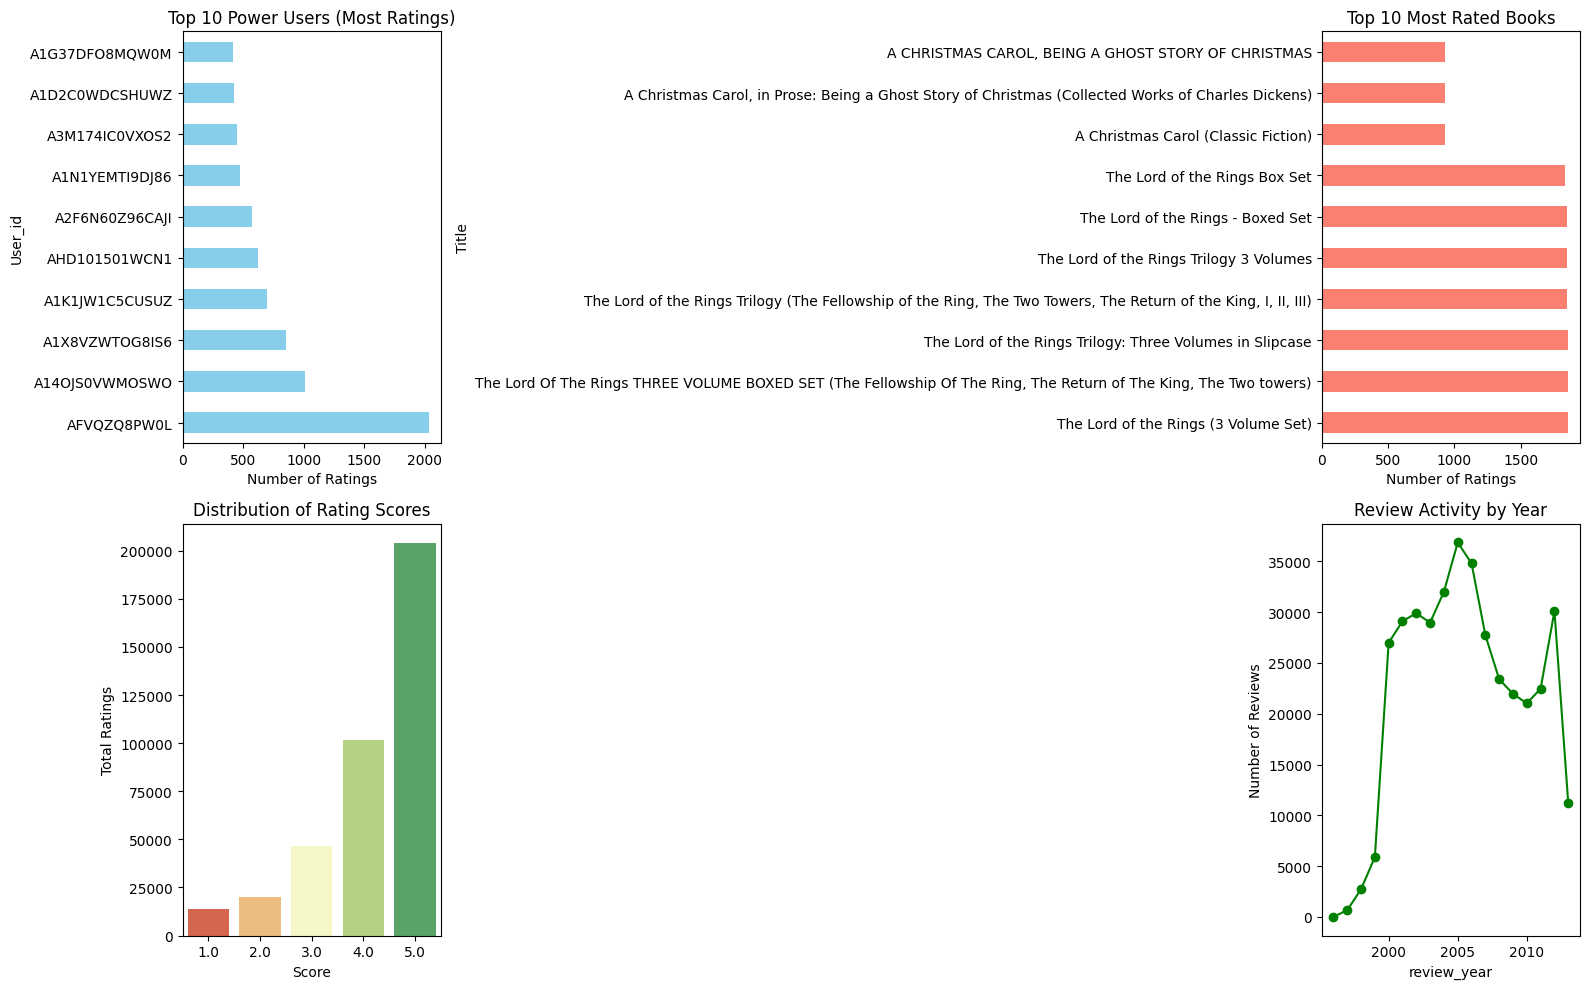

The most active user is: AFVQZQ8PW0L with 2033 ratings.


In [21]:
# ============================================================
# CELL 13 - Final EDA: Power Users, Popularity, and Bias
# ============================================================
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Power Users: Who are our top 10 reviewers?
top_users = combined_data['User_id'].value_counts().head(10)

# 2. Popular Books: Which books have the most collective behavior?
top_books = combined_data['Title'].value_counts().head(10)

# 3. Rating Distribution: Is there a positivity bias?
rating_counts = combined_data['rating'].value_counts().sort_index()

# Visualization
plt.figure(figsize=(16, 10))

# Plot 1: Top Users
plt.subplot(2, 2, 1)
top_users.plot(kind='barh', color='skyblue')
plt.title('Top 10 Power Users (Most Ratings)')
plt.xlabel('Number of Ratings')

# Plot 2: Top Books
plt.subplot(2, 2, 2)
top_books.plot(kind='barh', color='salmon')
plt.title('Top 10 Most Rated Books')
plt.xlabel('Number of Ratings')

# Plot 3: Ratings Distribution
plt.subplot(2, 2, 3)
sns.barplot(x=rating_counts.index, y=rating_counts.values, palette='RdYlGn')
plt.title('Distribution of Rating Scores')
plt.ylabel('Total Ratings')
plt.xlabel('Score')

# Plot 4: Activity Over Time
plt.subplot(2, 2, 4)
combined_data['review_year'].value_counts().sort_index().plot(kind='line', marker='o', color='green')
plt.title('Review Activity by Year')
plt.ylabel('Number of Reviews')

plt.tight_layout()
plt.show()

# Print the top user for the "Similar People" test
print(f"The most active user is: {top_users.index[0]} with {top_users.values[0]} ratings.")